In [ ]:
from src.propensity_score_estimator import PropensityScoreEstimator
import numpy as np
import torch
from sklearn.metrics import root_mean_squared_error, mean_absolute_error

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns

The `class` $\texttt{PropensityScoreEstimator}$ inherits the `class` $\texttt{MotivatingExample}$. If the $X$ and $M$ not specified, it takes default to generate dataset of $\texttt{MotivatingExample}$. The default of $\texttt{MotivatingExample}$ is the MAR motivating example with $d=3$. We can specify $d=2$ to instantiate $\texttt{PropensityScoreEstimator}$. The method $\texttt{.get\_X()}$ inherited from $\texttt{MotivatingExample}$ generates new sampel for test.

In [21]:
B = 100
results = np.empty((B, 4))

# for i in range(B):
#     pse = PropensityScoreEstimator(d=2)
#     X = pse.X
#     M = pse.M
#     Xtest = pse.get_X()
#     psg = pse.estimate_propensity_score_gmm(Xtest)
#     psn = pse.estimate_propensity_score_nmm(Xtest)
#     pst = pse.true_score_motivating_example_mar(Xtest)
#     maeg = mean_absolute_error(pst, psg)
#     maen = mean_absolute_error(pst, psn)
#     rmseg = root_mean_squared_error(pst, psg)
#     rmsen = root_mean_squared_error(pst, psn)
#     results[i] = maeg, maen, rmseg, rmsen

In [22]:
def work():
    pse = PropensityScoreEstimator(d=2)
    X = pse.X
    M = pse.M
    Xtest = pse.get_X()
    psg = pse.estimate_propensity_score_gmm(Xtest)
    psn = pse.estimate_propensity_score_nmm(Xtest)
    pst = pse.true_score_motivating_example_mar(Xtest)
    maeg = mean_absolute_error(pst, psg)
    maen = mean_absolute_error(pst, psn)
    rmseg = root_mean_squared_error(pst, psg)
    rmsen = root_mean_squared_error(pst, psn)
    return maeg, maen, rmseg, rmsen

In [23]:
from joblib import Parallel, delayed

results = Parallel(n_jobs=15)(
    delayed(work)() 
    for _ in range(B)
)

In [24]:
results = np.array(results)

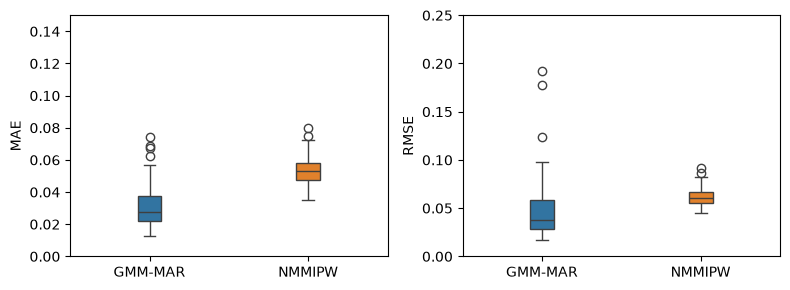

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3))

# Left subplot: compare MAE
sns.boxplot(data=results[:, :2], ax=axes[0], width=0.15)
# axes[0].set_title("MAE Comparison")
axes[0].set_xticks([0, 1], labels=["GMM-MAR", "NMMIPW"])
axes[0].set_ylabel("MAE")
axes[0].set_ylim(0, 0.15)

# Right subplot: compare RMSE
sns.boxplot(data=results[:, 2:4], ax=axes[1], width=0.15)
# axes[1].set_title("RMSE Comparison")
axes[1].set_xticks([0, 1], labels=["GMM-MAR", "NMMIPW"])
axes[1].set_ylabel("RMSE")
axes[1].set_ylim(0, 0.25)

plt.tight_layout()

plt.savefig('results/propensity_score1.png',dpi=300,
    bbox_inches="tight",)

plt.show()

Below is part of the code for produing comparison conditional on the value of $X_1$.

In [2]:
X1s = [-0.5, 0, 0.5]

In [3]:


colors = ["#0072B2", "#009E73", "#D55E00"]
markers = ["o", "*", "x"]
labels = ["Truth", "GMM-MAR", "NMMIPW"]

legend_handles = [
    Line2D(
        [0], [0],
        color=color,
        marker=marker,
        linestyle="None",
        markersize=8,
        label=label
    )
    for color, marker, label in zip(colors, markers, labels)
]
# fig, axes = plt.subplots(1, 3, figsize=(15, 4))
# fig.legend(handles=legend_handles, loc="upper center", ncol=3)
# plt.show()

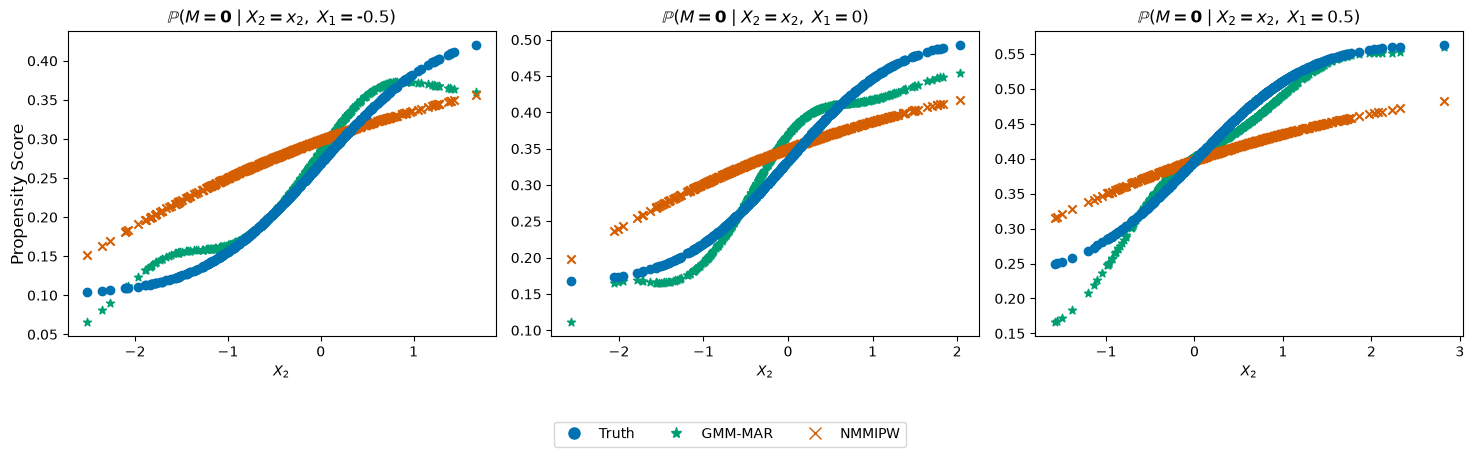

In [4]:
ntest = 500

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

pse_x1 = PropensityScoreEstimator(d=2)

for x1, ax in zip(X1s, axes):
    X1test = x1 * torch.ones(ntest)
    X2test = pse_x1._conditional(X1test)
    Xtest = torch.stack([X1test, X2test], dim=1)
    ax.scatter(X2test, pse_x1.estimate_propensity_score_gmm(Xtest), marker='*', c="#009E73")
    ax.scatter(X2test, pse_x1.estimate_propensity_score_nmm(Xtest), marker='x', c="#D55E00")
    ax.scatter(X2test, pse_x1.true_score_motivating_example_mar(Xtest), marker='o', c="#0072B2")
    ax.set_title(r'$\mathbb{P} (M = \mathbf{0} \mid X_2 = x_2, \; X_1 = $' + f'{x1})')
    ax.set_xlabel('$X_2$')

fig.supylabel('Propensity Score')
fig.legend(handles=legend_handles, loc="upper center", ncol=3, 
    bbox_to_anchor=(0.5, -0.05),)

plt.tight_layout()
plt.savefig('results/propensity_score2.png',dpi=300,
    bbox_inches="tight",)

plt.show()

$$
\mathbb P(M=0 \mid X=x) = \frac{p (X=x \mid M=0) \mathbb P(M=0)}{p(x)}
$$

- Estimate $p(X)$, $\mathbb P (M=\mathbf0)$ and $p(X \mid M=\mathbf0)$ on train data